# Pathfinding on the pore graph

This notebook shows how to find **paths between pockets** on mofography's **canonical periodic pore graph**: hop-count shortest paths, maximum-bottleneck ("widest") paths, and how accumulated **cell shifts** along a route reveal periodic wrap.

Prerequisites: [distance grid](distance_grid.qmd) and periodic segmentation (as in [PLD and percolation (winding method)](pld_and_percolation.ipynb)).

::: {.callout-warning}
## Not for PLD or percolation

This notebook is about **path finding** (shortest / widest / candidate routes between pockets). It does **not** show how to compute **PLD**, **LIS**, or axis **percolation** — use [PLD and percolation (winding method)](pld_and_percolation.ipynb) instead.

The winding method runs on the same periodic pore graph and detects cycles whose **net lattice shift** is non-zero (true percolation along an axis). A Dijkstra-style search on the older **distinct** region adjacency graph (one node per segmented region / PBC image, no shift vectors) cannot distinguish a channel that wraps the cell from a closed loop in the unit cell.
:::


## Imports

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

import heapq
from collections import deque

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from ase.io import read

import mofography as mgr
from mofography.winding_percolation import (
    _iter_neighbor_edges,
    make_directed_graph_from_segmentation_results,
    percolation_winding_multidigraph,
)

pio.renderers.default = "png"


## Segment the structure

We use **IRMOF-1** (`examples/TestCIFs/P1-IRMOF-1.cif`) and the same periodic segmentation entry point as the winding PLD tutorial. The result dict `seg` holds the distance grid, watershed regions, connections, and `maxima_info` needed to build the periodic pore graph.


In [2]:
atoms = read("../examples/TestCIFs/P1-IRMOF-1.cif")
spacing = 0.5
dgrid = mgr.dgrid_from_atoms_rust(atoms, spacing=spacing)
seg = mgr.do_periodic_segmentation_rust(
    dgrid.astype(np.float32),
    atoms,
    mask_thickness=0.05,
    h=0.2,
    min_distance=1.5,
    threshold_abs=1.5,
    spacing=spacing,
    compute_connections=True,
    return_dgrid=True,
    disable_tqdm=True,
)
print(f"canonical pockets (maxima_pbc): {len(seg['maxima_pbc'])}")


[RAYON] current_num_threads = 14
[RAYON] current_num_threads = 14


canonical pockets (maxima_pbc): 8


## The periodic pore graph

**Nodes** are **unit-cell pocket representatives** — one node per entry in `maxima_pbc` (the deduplicated pockets returned by periodic segmentation). Node attributes include `pocket_radius` (Å) and fractional coordinates `frac_pos`.

**Edges** are **windows** between pockets. Each edge is stored once with canonical ordering `i <= j` and carries:

- `relative_offset`: integer tuple `(n_a, n_b, n_c)` — how many unit-cell lengths you must shift pocket `j` to reach the periodic image connected to pocket `i`.
- `window_radius` / `window_radii`: limiting window size(s) along that connection (Å).

Traversals treat edges as **undirected** but must add or subtract `relative_offset` depending on direction (see `_iter_neighbor_edges` in `mofography/winding_percolation.py`). A **cycle whose accumulated offset is non-zero** is a winding loop and signals **percolation** along those axes — this is what `percolation_winding_multidigraph` evaluates.

**Distinct RAG** (`rag_from_connections`, `get_rag_from_regions_and_grid`): one node per segmented region label, including separate nodes for periodic images grouped only by PBC metadata — **no shift vector on edges**. That graph is useful for region topology plots, but it is the wrong object for winding percolation or shift-aware path finding.


In [3]:
G = make_directed_graph_from_segmentation_results(seg)
percolates, loops, acc_offsets = percolation_winding_multidigraph(G)

print(
    f"periodic pore graph: {G.number_of_nodes()} pockets, {G.number_of_edges()} directed window records"
)
print("axis percolation (any winding loop):", percolates)
if loops:
    example = loops[0]
    print(
        "example winding loop:",
        "winding =",
        example["winding"],
        "pockets =",
        example["nodes"],
    )


periodic pore graph: 8 pockets, 24 directed window records
axis percolation (any winding loop): {'x': True, 'y': True, 'z': True}
example winding loop: winding = (0, 0, -1) pockets = [1, 2]


## Path-finding helpers on the periodic graph

Below, `_iter_neighbor_edges` mirrors the traversal rules used by `percolation_winding_multidigraph`: outgoing edges add `relative_offset`; incoming edges subtract it.


In [4]:
def reconstruct_path(parent, dst):
    nodes, edge_steps = [dst], []
    cur = dst
    while parent[cur][0] is not None:
        prev, step = parent[cur]
        edge_steps.append(step)
        nodes.append(prev)
        cur = prev
    nodes.reverse()
    edge_steps.reverse()
    return nodes, edge_steps


def shortest_pocket_path(G, src, dst):
    """Unweighted shortest path (fewest windows)."""
    if src == dst:
        return [src], [], (0, 0, 0)
    parent = {src: (None, None)}
    queue = deque([src])
    while queue:
        u = queue.popleft()
        for nbr, key, canonical_offset, delta, forward in _iter_neighbor_edges(G, u):
            if nbr in parent:
                continue
            data = G[u][nbr][key] if forward else G[nbr][u][key]
            step = {
                "u": u,
                "v": nbr,
                "key": key,
                "delta": delta,
                "window_radius": float(data.get("window_radius", 0.0)),
            }
            parent[nbr] = (u, step)
            if nbr == dst:
                queue.clear()
                break
            queue.append(nbr)
    if dst not in parent:
        raise ValueError(f"No path from pocket {src} to pocket {dst}")
    nodes, steps = reconstruct_path(parent, dst)
    net_shift = tuple(int(x) for x in np.sum([s["delta"] for s in steps], axis=0))
    return nodes, steps, net_shift


def widest_pocket_path(G, src, dst):
    """Maximum-bottleneck path: maximize the minimum window radius along the route."""
    if src == dst:
        return [src], [], float(G.nodes[src]["pocket_radius"]), (0, 0, 0)
    best = {src: float("inf")}
    parent = {src: (None, None)}
    heap = [(-float("inf"), src)]
    settled = set()
    while heap:
        neg_score, u = heapq.heappop(heap)
        if u in settled:
            continue
        settled.add(u)
        if u == dst:
            break
        for nbr, key, canonical_offset, delta, forward in _iter_neighbor_edges(G, u):
            if nbr in settled:
                continue
            data = G[u][nbr][key] if forward else G[nbr][u][key]
            wr = float(data.get("window_radius", 0.0))
            bottleneck = min(best[u], wr)
            if nbr not in best or bottleneck > best[nbr]:
                best[nbr] = bottleneck
                parent[nbr] = (
                    u,
                    {
                        "u": u,
                        "v": nbr,
                        "key": key,
                        "delta": delta,
                        "window_radius": wr,
                    },
                )
                heapq.heappush(heap, (-bottleneck, nbr))
    if dst not in parent:
        raise ValueError(f"No path from pocket {src} to pocket {dst}")
    nodes, steps = reconstruct_path(parent, dst)
    net_shift = tuple(int(x) for x in np.sum([s["delta"] for s in steps], axis=0))
    return nodes, steps, best[dst], net_shift


def path_to_dataframe(nodes, steps, net_shift):
    rows = []
    for i, step in enumerate(steps, start=1):
        rows.append(
            {
                "hop": i,
                "from_pocket": step["u"],
                "to_pocket": step["v"],
                "cell_shift": step["delta"],
                "window_radius_A": step["window_radius"],
            }
        )
    df = pd.DataFrame(rows)
    df.attrs["net_cell_shift"] = net_shift
    df.attrs["pockets"] = nodes
    return df


### Shortest path (fewest windows)

We choose pockets **2 → 5** on IRMOF-1; the hop-minimal route crosses a periodic window so the **net cell shift** is `(0, 1, 0)`.


In [5]:
src_pocket, dst_pocket = 2, 5
short_nodes, short_steps, short_shift = shortest_pocket_path(G, src_pocket, dst_pocket)
short_df = path_to_dataframe(short_nodes, short_steps, short_shift)
print("pocket sequence:", short_nodes)
print("net cell shift:", short_shift)
short_df


pocket sequence: [2, 4, 6, 5]
net cell shift: (0, 1, 0)


,hop,from_pocket,to_pocket,cell_shift,window_radius_A
0,1,2,4,"(0, 0, 0)",3.677834
1,2,4,6,"(0, 0, 0)",3.677834
2,3,6,5,"(0, 1, 0)",3.710039


### Widest path (maximum bottleneck)

The same endpoints, but maximizing the minimum window radius along the route (a max-min / widest path).


In [6]:
wide_nodes, wide_steps, wide_bn, wide_shift = widest_pocket_path(G, src_pocket, dst_pocket)
wide_df = path_to_dataframe(wide_nodes, wide_steps, wide_shift)
print(f"bottleneck window radius: {wide_bn:.3f} Å")
print("net cell shift:", wide_shift)
wide_df


bottleneck window radius: 3.710 Å
net cell shift: (-1, 1, 0)


,hop,from_pocket,to_pocket,cell_shift,window_radius_A
0,1,2,1,"(0, 0, -1)",3.710039
1,2,1,6,"(-1, 0, 1)",3.710039
2,3,6,5,"(0, 1, 0)",3.710039


### Quick visualization

A translucent void surface for context (static PNG renderer).


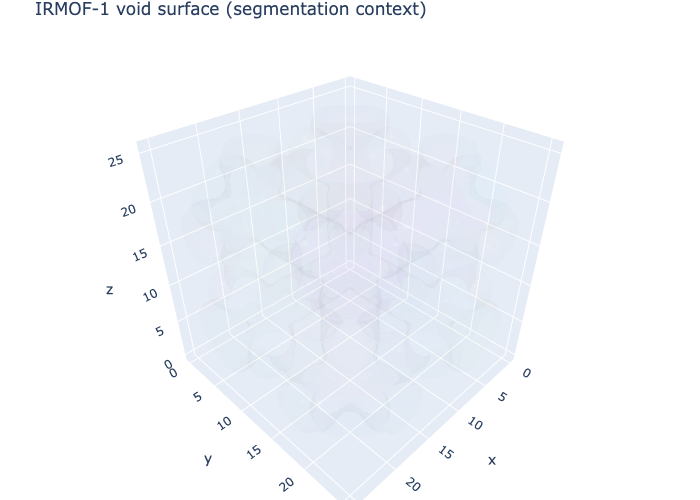

In [7]:
fig = go.Figure()
fig.add_trace(
    mgr.plot_surface_dgrid(
        seg["dgrid"],
        isovalue=1.0,
        ase_atoms=atoms,
        region_labels=seg["regions"],
        stylize=True,
        opacity=0.12,
    )
)
fig.update_layout(title="IRMOF-1 void surface (segmentation context)", showlegend=False)
fig.show()


## Older approach (distinct graph; experimental)

The functions below search for **candidate percolation paths** on the **distinct** region adjacency graph (`rag_from_connections` / `get_rag_from_regions_and_grid`): one node per segmented region label, periodic images as separate nodes, **no lattice shift on edges**. They were an early approximation for straight channels and **must not** be used for PLD, LIS, or winding percolation.

The cell is shown for reference; it is not executed here because it requires the legacy `regions_from_dgrid` pipeline (distinct from `do_periodic_segmentation_rust`).


In [8]:
# | eval: false
# Legacy distinct-graph path search (do not use for PLD / percolation):
#
# regions, maxima = mgr.regions_from_dgrid(dgrid, mask_thickness=0.05)
# connections = mgr.connections_from_regions_and_dgrid(regions, dgrid, maxima, atoms)
# rag = mgr.rag_from_connections(connections, maxima, only_use_internal=False)
# rag.graph.update({"regions": regions, "connections": connections, "ase_atoms": atoms})
# paths, path_windows, path_lengths = mgr.get_percolated_paths_on_rag(rag)
# filtered_paths, *_ = mgr.filter_percolated_paths(paths, path_windows, path_lengths, probe_radius=1.0)
# path_groups = mgr.find_isomorphic_path_groups(filtered_paths[:50], rag)


## Where to go next

- **PLD, LIS, percolation history, winding clusters:** [PLD and percolation (winding method)](pld_and_percolation.ipynb)
- **Face merging vs winding:** [Face merging vs winding](face_merging_vs_winding.qmd)
